In [1]:
pip install pandas numpy matplotlib seaborn scikit-learn tensorflow transformers datasets torch

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns



In [4]:
df = pd.read_csv("../dataset/IMDB Dataset.csv")

df.head()

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [6]:
print("Dataset Shape=", df.shape)


Dataset Shape= (50000, 2)


In [7]:
print("Dataset Information=")
df.info()



Dataset Information=
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   review     50000 non-null  object
 1   sentiment  50000 non-null  object
dtypes: object(2)
memory usage: 781.4+ KB


In [9]:
print("Missing Values=")
print(df.isnull().sum())

Missing Values=
review       0
sentiment    0
dtype: int64


In [11]:
print("Duplicate Reviews=")
print(df.duplicated().sum())

Duplicate Reviews=
418


In [ ]:
df = df.drop_duplicates(subset=["review"])

print("Dataset Shape After Removing Duplicates=", df.shape)


Dataset Shape After Removing Duplicates: (49582, 2)


In [15]:
df.duplicated().sum()

np.int64(0)

sentiment
positive    24884
negative    24698
Name: count, dtype: int64


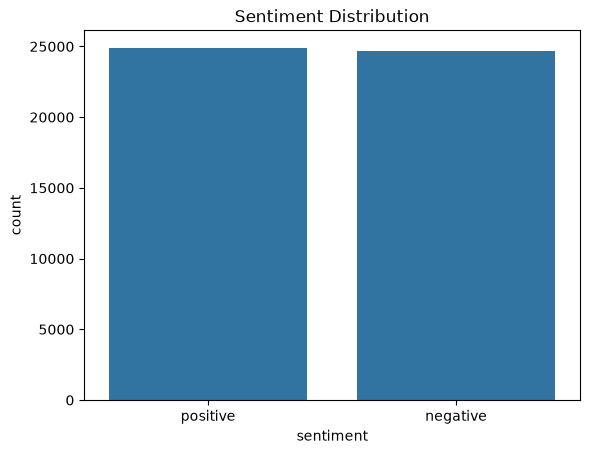

In [16]:
print(df["sentiment"].value_counts())

sns.countplot(data=df, x="sentiment")
plt.title("Sentiment Distribution")
plt.show()

In [19]:
import re
from html import unescape

def clean_text(text):
    text = unescape(text)
    text = re.sub(r'<.*?>', ' ', text)
    text = re.sub(r'\s+', ' ', text)
    return text.strip()

df["clean_review"] = df["review"].apply(clean_text)

print("Original Review=")
print(df["review"].iloc[0][:300])

print("\nCleaned Review=")
print(df["clean_review"].iloc[0][:300])

Original Review=
One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Tru

Cleaned Review=
One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me. The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this


In [21]:
df["label"] = df["sentiment"].map({
    "positive": 1,
    "negative": 0
})

print(df[["sentiment", "label"]].head())



  sentiment  label
0  positive      1
1  positive      1
2  positive      1
3  negative      0
4  positive      1


In [23]:
print("Label Distribution=")
print(df["label"].value_counts())

Label Distribution=
label
1    24884
0    24698
Name: count, dtype: int64


In [24]:
from sklearn.model_selection import train_test_split

X = df["clean_review"]
y = df["label"]


X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)


X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)



In [26]:
print("Training samples=", len(X_train))
print("Validation samples=", len(X_val))
print("Testing samples=", len(X_test))

Training samples= 34707
Validation samples= 7437
Testing samples= 7438


In [ ]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

MAX_WORDS = 20000
MAX_LEN = 300

tokenizer = Tokenizer(
    num_words=MAX_WORDS,
    oov_token="<OOV>"
)

tokenizer.fit_on_texts(X_train)
X_train_seq = tokenizer.texts_to_sequences(X_train)
X_val_seq = tokenizer.texts_to_sequences(X_val)
X_test_seq = tokenizer.texts_to_sequences(X_test)

Original Review:
I work in a library and expected to like this movie when it came out 5 years ago. Well I liked Parker Posey a lot (she's a wonderful actress) and Omar Townsend was really cute as her boyfriend (he cou

Converted Sequence:
[10, 160, 8, 4, 3354, 3, 851, 6, 37, 11, 15, 51, 9, 382, 42, 453, 152, 618, 70, 10, 431, 2487, 8463, 4, 168, 458, 4, 395, 543, 3]


In [28]:
print("Original Review:")
print(X_train.iloc[0][:200])



Original Review:
I work in a library and expected to like this movie when it came out 5 years ago. Well I liked Parker Posey a lot (she's a wonderful actress) and Omar Townsend was really cute as her boyfriend (he cou


In [29]:
print("\nConverted Sequence:")
print(X_train_seq[0][:30])


Converted Sequence:
[10, 160, 8, 4, 3354, 3, 851, 6, 37, 11, 15, 51, 9, 382, 42, 453, 152, 618, 70, 10, 431, 2487, 8463, 4, 168, 458, 4, 395, 543, 3]


In [30]:
X_train_pad = pad_sequences(
    X_train_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

X_val_pad = pad_sequences(
    X_val_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

X_test_pad = pad_sequences(
    X_test_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)



In [32]:


print("Training Shape:", X_train_pad.shape)
print("Validation Shape:", X_val_pad.shape)
print("Testing Shape:", X_test_pad.shape)

Training Shape: (34707, 300)
Validation Shape: (7437, 300)
Testing Shape: (7438, 300)
